<div><center><img src="https://ml.ucv.ai/logo.png" width="150"/></center></div>

# 0 Del texto a los Transformers: embeddings, atención y modelos preentrenados

**Redes Neuronales Profundas · Escuela de Computación, Facultad de Ciencias · UCV**

Esta clase recorre, en una sola sesión de cuatro horas, el camino que va desde la pregunta *¿cómo se representa un texto con números?* hasta los modelos que hoy dominan el área: los Transformers. El hilo conductor es una sola idea, que aparece tres veces con distinto nivel de sofisticación:

1. **Embeddings estáticos:** cada palabra es un vector fijo, sin importar el contexto.
2. **Atención:** cada elemento de una secuencia construye su representación mirando a los demás.
3. **Transformers:** bloques de atención apilados, que se aplican igual a palabras (BERT) que a parches de una imagen (ViT).

**Basado en**

- Vaswani et al. (2017). *Attention is all you need*. NeurIPS. [arXiv:1706.03762](https://arxiv.org/abs/1706.03762)
- Devlin et al. (2019). *BERT: Pre-training of deep bidirectional Transformers for language understanding*. NAACL. [arXiv:1810.04805](https://arxiv.org/abs/1810.04805)
- Dosovitskiy et al. (2021). *An image is worth 16x16 words: Transformers for image recognition at scale*. ICLR. [arXiv:2010.11929](https://arxiv.org/abs/2010.11929)
- Zhai et al. (2022). *Scaling Vision Transformers*. CVPR. [arXiv:2106.04560](https://arxiv.org/abs/2106.04560)
- Abnar & Zuidema (2020). *Quantifying attention flow in Transformers*. ACL. [arXiv:2005.00928](https://arxiv.org/abs/2005.00928)
- Cañete et al. (2020). *Spanish pre-trained BERT model and evaluation data* (BETO). [GitHub](https://github.com/dccuchile/beto)
- Prince, S. *Understanding Deep Learning*, cap. 12 (Transformers).
- Material de apoyo: [Pretrained word embeddings (Keras)](https://keras.io/examples/nlp/pretrained_word_embeddings/), [Starsconf: word embeddings](https://github.com/mquezada/starsconf2018-word-embeddings), [Spanish word embeddings (DCC, U. de Chile)](https://github.com/dccuchile/spanish-word-embeddings), [Tutorial de BertViz](https://github.com/jessevig/bertviz), y el material sobre *self-attention* y Vision Transformers de la asignatura *Artificial Neural Networks and Deep Learning* (KU Leuven).

Ejecuten con GPU: *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU T4*.

## Objetivos

- explicar qué hace un *tokenizer* de subpalabras y por qué se usa;
- distinguir un embedding estático de uno contextual, y mostrarlo con un ejemplo;
- escribir el mecanismo de atención con sus dimensiones, $\mathrm{softmax}(QK^T/\sqrt{d_k})\,V$, y explicar qué representan $Q$, $K$ y $V$;
- describir las piezas de un bloque Transformer

Las celdas marcadas con tardan más de un minuto; el tiempo indicado es para una GPU T4.

# 0. Configuración

In [ ]:
!nvidia-smi

In [ ]:
import os
# La sección 2 usa Keras con entradas de texto: solo el backend de TensorFlow lo admite.
# Hay que fijarlo ANTES de importar keras por primera vez.
os.environ["KERAS_BACKEND"] = "tensorflow"

!pip -q install gensim einops bertviz

import math, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, Subset
from einops import rearrange
from transformers import AutoTokenizer, AutoModel

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

SEED = 42
def fijar_semilla(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

fijar_semilla()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| dispositivo:", device)

# 1. Del texto a los vectores

Una red neuronal solo opera con números. Antes de clasificar, traducir o resumir un texto, hay que decidir **cómo convertirlo en vectores**, y esa decisión condiciona todo lo que viene después.

## 1.1 Un problema concreto: detección de correos *spam*

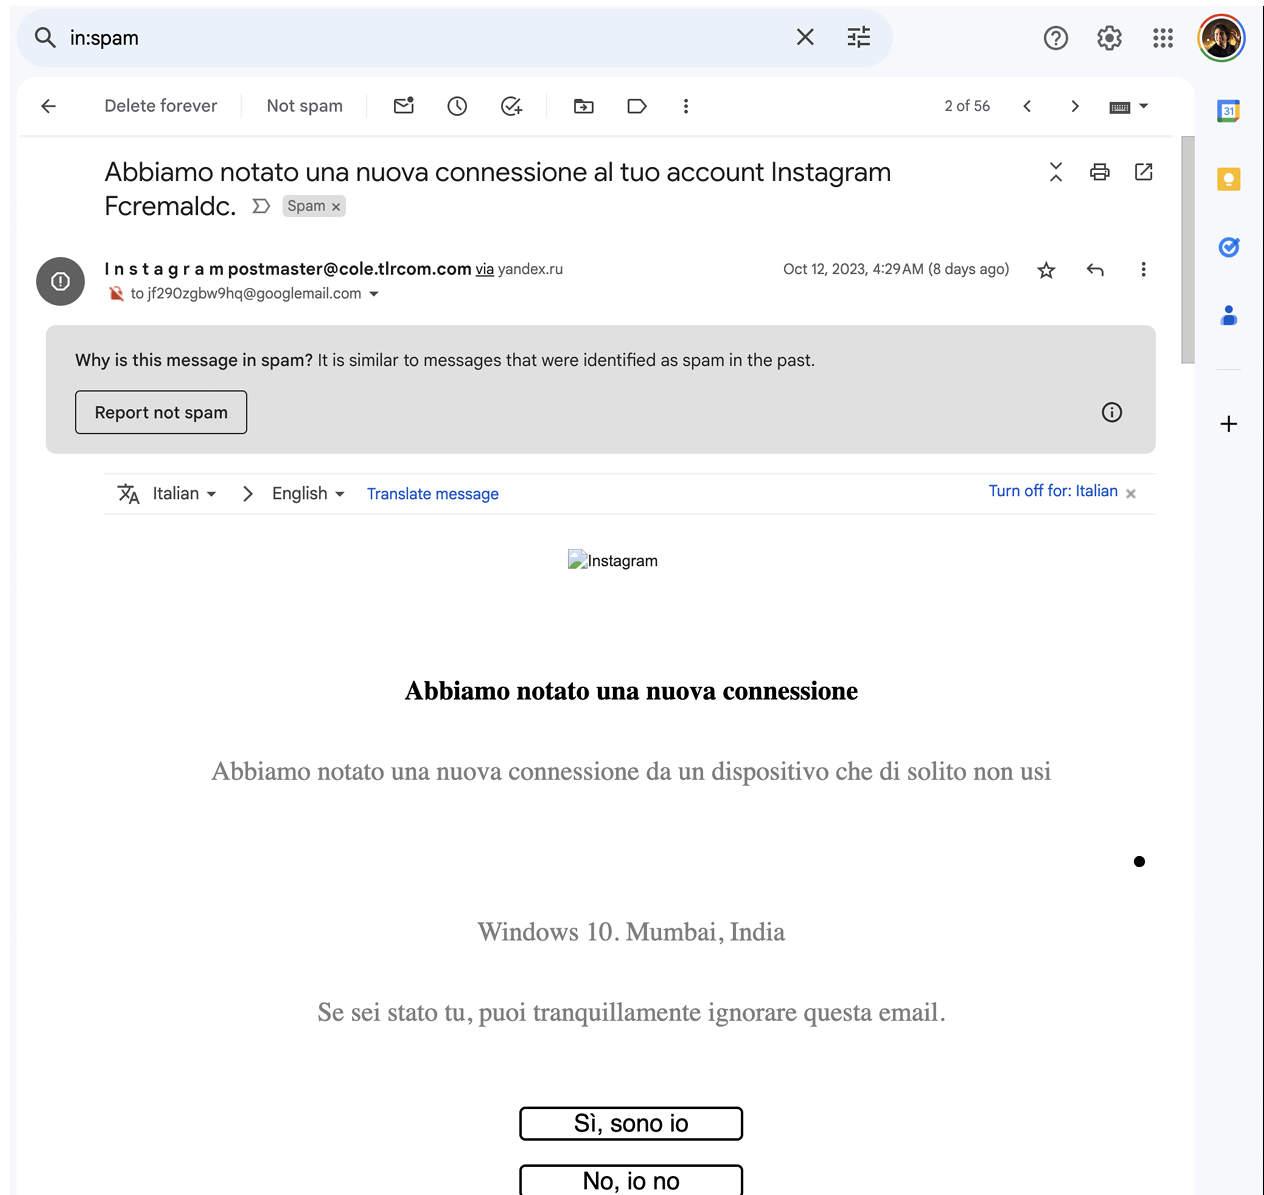

1. **Problema:** Determinar si un correo electrónico es *spam* o no.
1. **¿Cuál es la función?** 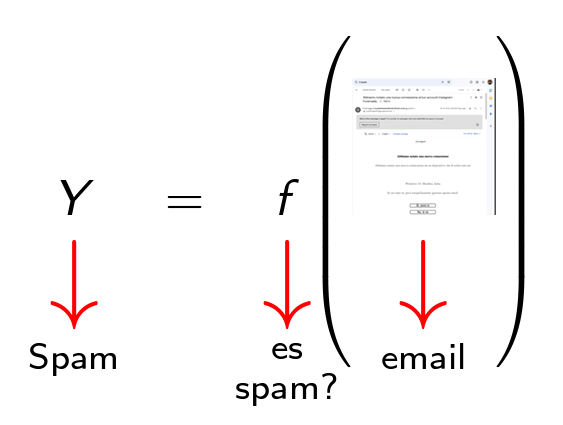
1. **¿Cómo definir la representación?** Defino $X$ como el conjunto de secuencias que representan documentos de texto.
$$ X = \{x_1, x_2, x_3, \ldots, x_N\} $$
    - Donde:
        1. $x_i$ representa una secuencia de caracteres arbitraria.
        1. $N$ es el número de secuencias disponibles.

    - Discusión
        1. Cada $x_i$ puede contener palabras, frases o caracteres que conforman el contenido del documento.
        1. El objetivo de la función es etiquetar cada $x_i$ como "spam" o "no spam" según su contenido.

Es fácil conocer el rango de la función $$f(x_i) \in \{ spam, no\;\;spam \}$$

Ahora, supongamos que intentamos representar todas las oraciones y de alguna manera obtenemos $f$

1. $f(\textbf{Abbiamo notato una nuova connessione}) = spam$
1. $f(\textbf{Abbiamo notato una nuova}) = spam$
1. $\cdots$
1. $f(\textbf{Abbiamo})=?$

Buscamos resolver el mismo problema pero se pueden tener muchos enfoques:

1. **Diccionario de Palabras:** Se tiene un diccionario que asigna cada palabra a un índice único.
$$ \text{Diccionario: } w_i \rightarrow i $$
1. **Matriz de Embedding:** Se utiliza una matriz de embedding para representar cada palabra como un vector de características.
$$\text{Embedding de } w_i: \vec{v}_i \in \mathbb{R}^d $$
  - Ejemplo: Si $d = 3$ (vectores tridimensionales), el embedding de la palabra "manzana" puede ser representado como $$\vec{v}_{\text{manzana}} = [0.2, 0.8, 0.5]$$.
  - No solo eso, en el futuro podremos hacer:
  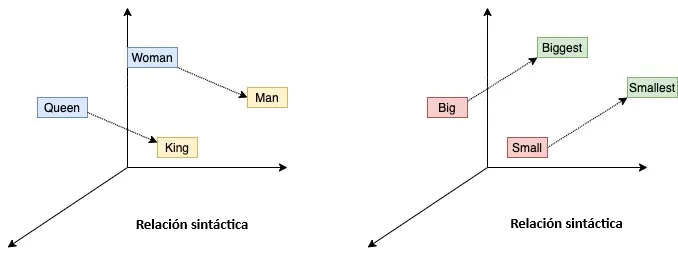

  
Figura: [Nikhil Birajdar](https://towardsdatascience.com/word2vec-research-paper-explained-205cb7eecc30).

## 1.2 Tokenización: del texto a los índices

Antes de usar cualquier modelo hay que convertir el texto en **tokens**, unidades con un índice en un vocabulario. Eso lo hace el *tokenizer*. Hay tres granularidades típicas:

- **Por palabra**: `["Hola", "mundo"]`. Vocabularios enormes y palabras desconocidas por todas partes.
- **Por subpalabra**: `["Ho", "##la", "mundo"]`. Es lo que usan BERT y casi todos los Transformers.
- **Por carácter**: `["H", "o", "l", "a"]`. Vocabulario mínimo, pero secuencias muy largas.

In [ ]:
tok_multi = AutoTokenizer.from_pretrained("bert-base-multilingual-cased")

texto = "Hola mundo"
ids = tok_multi.encode(texto)
print("Tokens:          ", tok_multi.tokenize(texto))
print("Índices:         ", ids)
print("Tokens con índice:", tok_multi.convert_ids_to_tokens(ids))

Noten que `encode` agrega dos tokens especiales: `[CLS]` al inicio, cuyo vector final se usa como resumen de toda la secuencia para clasificar, y `[SEP]` al final, que separa oraciones. Los vamos a volver a ver en las secciones 4 y 5.

### ¿Qué significa el `##` en los tokens?

El tokenizer de BERT (*WordPiece*) intenta dividir el texto en las unidades más frecuentes posibles. Si una palabra completa no está en el vocabulario, la parte en fragmentos que sí están. El prefijo `##` indica que ese fragmento **continúa** la palabra anterior; no es el comienzo de una palabra nueva.

¿Por qué se hace esto?

1. Reduce el tamaño del vocabulario: no hace falta guardar todas las palabras del idioma.
2. Maneja palabras desconocidas: si una palabra no está, probablemente sus fragmentos sí.
3. Permite representar palabras nuevas o raras, como *recomiéndamelo*, sin que el modelo se pierda.

Es especialmente útil en idiomas con morfología rica, como el español. Comparemos el tokenizer **multilingüe** (104 idiomas comparten un vocabulario) con el de **BETO**, un BERT entrenado solo con texto en español:

In [ ]:
tok_beto = AutoTokenizer.from_pretrained("dccuchile/bert-base-spanish-wwm-cased")

palabras = ["terrateniente", "prehistoria", "histología", "recomiéndamelo", "inconstitucionalmente", "chamo"]
pd.DataFrame([{"palabra": p,
               "BERT multilingüe": " ".join(tok_multi.tokenize(p)),
               "BETO (español)": " ".join(tok_beto.tokenize(p))} for p in palabras])

**Qué observar:** con un vocabulario construido para el español, las palabras se parten en menos fragmentos y los fragmentos suelen coincidir con prefijos, raíces y sufijos reales. Por ejemplo, *histología* viene del griego *histos* (tejido) y *logos* (estudio): la ciencia de los tejidos. Un tokenizer que respeta esas piezas le facilita al modelo generalizar. El vocabulario del tokenizer es parte del modelo: no se puede usar el tokenizer de uno con los pesos de otro.

## 1.3 Embeddings estáticos: un vector por palabra

Un **embedding** asigna a cada palabra $w$ un vector $\vec{v}_w \in \mathbb{R}^d$, aprendido de forma que palabras que aparecen en contextos parecidos queden cerca (la hipótesis distribucional: *una palabra se conoce por las compañías que frecuenta*). Word2vec, GloVe y FastText producen embeddings **estáticos**: una sola tabla, un vector por palabra.

Usamos los vectores FastText entrenados por el DCC de la Universidad de Chile sobre el *Spanish Billion Words Corpus* (100 000 palabras, $d = 300$).

⏱ La descarga tarda alrededor de un minuto.

In [ ]:
if not os.path.exists("fasttext-sbwc.100k.vec"):
    !wget -q http://dcc.uchile.cl/~jperez/word-embeddings/fasttext-sbwc.100k.vec.gz
    !gzip -d -q fasttext-sbwc.100k.vec.gz

from gensim.models import KeyedVectors
we = KeyedVectors.load_word2vec_format("fasttext-sbwc.100k.vec", limit=100000)
print("vocabulario:", len(we.key_to_index), "palabras | dimensión:", we.vector_size)

### Vecinos y analogías

La operación clásica: si los embeddings capturan relaciones, entonces $\vec{v}_{\text{rey}} - \vec{v}_{\text{hombre}} + \vec{v}_{\text{mujer}}$ debería quedar cerca de $\vec{v}_{\text{reina}}$. `most_similar` busca las palabras cuyo vector tiene mayor similitud coseno con el resultado.

In [ ]:
def vecinos(**kwargs):
    return ", ".join(f"{w} ({s:.2f})" for w, s in we.most_similar(topn=6, **kwargs))

print("rey - hombre + mujer   →", vecinos(positive=["rey", "mujer"], negative=["hombre"]))
print("madrid - españa + italia →", vecinos(positive=["madrid", "italia"], negative=["españa"]))
print("vecinos de 'caracas'   →", vecinos(positive=["caracas"]))
print("vecinos de 'arepa'     →", vecinos(positive=["arepa"]))

### Visualizar las analogías

Proyectamos con PCA a dos dimensiones. En el primer ejemplo construimos un punto partiendo de *hombre*, en la dirección de *hombre → rey*, con la longitud del vector *mujer → reina*. Si la relación "masculino/femenino de la realeza" es aproximadamente un desplazamiento constante, los dos segmentos deberían verse paralelos.

In [ ]:
from sklearn.decomposition import PCA

def graficar_analogia(palabras, etiqueta_extra, vector_extra, titulo):
    vectores = np.array([we[w.lower()] for w in palabras] + [vector_extra])
    etiquetas = palabras + [etiqueta_extra]
    puntos = PCA(n_components=2).fit_transform(vectores)
    plt.figure(figsize=(8, 6))
    plt.scatter(puntos[:, 0], puntos[:, 1])
    for i, etiqueta in enumerate(etiquetas):
        plt.annotate(etiqueta, xy=(puntos[i, 0], puntos[i, 1]), fontsize=11)
    plt.title(titulo); plt.xlabel("componente 1"); plt.ylabel("componente 2")
    plt.show()

# Ejemplo 1: hombre + |reina - mujer| · dirección(hombre → rey)
direccion = we["rey"] - we["hombre"]
magnitud = np.linalg.norm(we["reina"] - we["mujer"])
vector = we["hombre"] + magnitud * direccion / np.linalg.norm(direccion)
graficar_analogia(["rey", "hombre", "mujer", "reina"], "hombre + |reina−mujer|·dir(hombre→rey)", vector,
                  "Aritmética de embeddings FastText (PCA)")

# Ejemplo 2: roma + |españa - madrid| · dirección(roma → italia)
direccion = we["italia"] - we["roma"]
magnitud = np.linalg.norm(we["españa"] - we["madrid"])
vector = we["roma"] + magnitud * direccion / np.linalg.norm(direccion)
graficar_analogia(["Roma", "Madrid", "España", "Italia"], "roma + |españa−madrid|·dir(roma→italia)", vector,
                  r"$\vec{Italia} \approx \vec{Roma} + |\vec{España} - \vec{Madrid}|_2 \cdot \vec{dirección}$ (PCA)")

**La limitación de fondo:** la tabla tiene **un solo vector por palabra**. *Banco* (el de la plaza) y *banco* (el que cobra comisiones) comparten vector, y ese vector termina siendo una mezcla de ambos significados. Fíjense en sus vecinos:

In [ ]:
print("vecinos de 'banco' →", vecinos(positive=["banco"]))

## 1.4 Embeddings contextuales: el vector depende de la frase

Un modelo como BERT no tiene una tabla de vectores finales: lee **la frase completa** y produce un vector por token que depende de todas las demás palabras. Cargamos BETO y definimos una función que lleva una lista de textos a un vector por texto: el promedio de los vectores de salida de la última capa sobre sus tokens.

In [ ]:
modelo_beto = AutoModel.from_pretrained("dccuchile/bert-base-spanish-wwm-cased").to(device).eval()
print("capas:", modelo_beto.config.num_hidden_layers, "| cabezas de atención:", modelo_beto.config.num_attention_heads,
      "| dimensión:", modelo_beto.config.hidden_size, "| parámetros:", f"{sum(p.numel() for p in modelo_beto.parameters()):,}")

@torch.no_grad()
def embeddings_bert(textos, tokenizer=tok_beto, modelo=modelo_beto, batch_size=256):
    '''Un vector por texto: promedio de los vectores de salida de la última capa sobre todos sus tokens
    (incluidos [CLS] y [SEP], excluido el relleno). Procesa los textos por lotes en la GPU.'''
    vectores = []
    for i in range(0, len(textos), batch_size):
        lote = tokenizer(list(textos[i:i + batch_size]), return_tensors="pt", padding=True, truncation=True, max_length=32).to(device)
        salida = modelo(**lote).last_hidden_state                   # (B, T, 768)
        mascara = lote["attention_mask"].unsqueeze(-1)              # (B, T, 1): 1 en tokens reales, 0 en relleno
        vectores.append(((salida * mascara).sum(1) / mascara.sum(1)).cpu().numpy())
    return np.concatenate(vectores)

### Interpretación semántica

Proyectamos los vectores de varias palabras y nombres propios con t-SNE (primero reducimos a 5 dimensiones con PCA). ¿Qué grupos aparecen?

In [ ]:
from sklearn.manifold import TSNE

palabras = ["amor", "odio", "felicidad", "tristeza",
            "computadora", "internet", "perro", "gato",
            "hospital", "médico", "ingeniero", "matemático",
            "España", "Italia", "Gran Bretaña", "Madrid",
            "AS Roma", "Real Madrid", "Liverpool", "Manchester City",
            "Alan Turing", "Albert Einstein", "Giorgio Parisi",
            "Oasis", "The Beatles", "Maneskin"]

vectores = embeddings_bert(palabras)
reducidos = TSNE(n_components=2, perplexity=5, random_state=SEED).fit_transform(PCA(n_components=5, random_state=SEED).fit_transform(vectores))

plt.figure(figsize=(10, 8))
plt.scatter(reducidos[:, 0], reducidos[:, 1])
for i, w in enumerate(palabras):
    plt.annotate(w, xy=(reducidos[i, 0], reducidos[i, 1]), fontsize=11, color="tab:red")
plt.title("Embeddings de BETO (t-SNE)"); plt.xlabel("dim 1"); plt.ylabel("dim 2")
plt.show()

### Similitud coseno, con un grupo de control

$$\cos(\vec{a}, \vec{b}) = \frac{\vec{a} \cdot \vec{b}}{\|\vec{a}\|\,\|\vec{b}\|}$$

¿Se parece *Madrid* + *fútbol* a *Real Madrid*? Antes de responder hay que mirar un control: los vectores promediados de BERT ocupan un cono estrecho del espacio (*anisotropía*), así que **todas** las similitudes coseno salen altas. Lo que informa es la comparación, no el número aislado.

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

madrid, futbol, real_madrid, computadora, receta = embeddings_bert(["Madrid", "fútbol", "Real Madrid", "computadora", "receta de cocina"])
compuesto = madrid + futbol
for nombre, v in [("Real Madrid", real_madrid), ("computadora", computadora), ("receta de cocina", receta)]:
    print(f"cos('Madrid' + 'fútbol', '{nombre}') = {cosine_similarity([compuesto], [v])[0, 0]:.3f}")

### El experimento clave: *banco* en cuatro frases

Extraemos el vector que BETO le asigna a la palabra *banco* dentro de cada frase y comparamos los cuatro vectores entre sí. Con FastText los cuatro serían **idénticos**.

In [ ]:
@torch.no_grad()
def vector_en_contexto(frase, palabra, tokenizer=tok_beto, modelo=modelo_beto):
    '''Vector de salida de BETO para `palabra` dentro de `frase` (promedio de sus subpalabras).'''
    enc = tokenizer(frase, return_tensors="pt").to(device)
    h = modelo(**enc).last_hidden_state[0]                          # (T, 768): un vector por token de la frase
    ids_palabra = tokenizer(palabra, add_special_tokens=False)["input_ids"]
    ids = enc["input_ids"][0].tolist()
    for i in range(len(ids) - len(ids_palabra) + 1):               # ubicar los tokens de la palabra en la frase
        if ids[i:i + len(ids_palabra)] == ids_palabra:
            return h[i:i + len(ids_palabra)].mean(0).cpu().numpy()
    raise ValueError(f"'{palabra}' no aparece en: {frase}")

frases = ["Me senté en el banco de la plaza a leer.",
          "El banco del parque estaba recién pintado.",
          "El banco me cobró una comisión por la transferencia.",
          "Deposité el cheque en el banco esta mañana."]
V = np.array([vector_en_contexto(f, "banco") for f in frases])
sim = cosine_similarity(V)

etiquetas = ["plaza", "parque", "comisión", "cheque"]
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(sim, annot=True, fmt=".2f", xticklabels=etiquetas, yticklabels=etiquetas, cmap="viridis", vmin=sim.min(), vmax=1)
plt.title("Similitud coseno de 'banco' según la frase (BETO)")
plt.show()

**Qué observar:** los dos *bancos* de asiento se parecen más entre sí que a los dos *bancos* financieros, y viceversa, aunque la palabra es la misma. ¿Cómo "sabe" BERT cuál es cuál? Mirando las demás palabras de la frase (*plaza*, *comisión*...) y mezclando su información en el vector de *banco*. Ese mecanismo de mirar y mezclar es la **atención**, el tema de la sección 3.

# 2. Aplicación: clasificación de compras con embeddings preentrenados (Keras)

Usamos el conjunto de **glosas de compras públicas** del DCC de la Universidad de Chile: descripciones cortas de órdenes de compra (*"colmax 125 mg, 10 comprimidos"*) etiquetadas con su categoría. El plan es el clásico de *transfer learning* con embeddings:

1. Construir un vocabulario con las glosas de entrenamiento.
2. Llenar una matriz de embeddings con el vector de BETO de cada palabra del vocabulario.
3. Usarla como una capa `Embedding` **congelada** y entrenar encima una red convolucional 1D.

⏱ Descarga y matriz de embeddings: alrededor de un minuto.

In [ ]:
if not os.path.exists("dataset_compras.tsv"):
    !wget -q http://users.dcc.uchile.cl/~mquezada/data-compras.zip
    !unzip -q -o data-compras.zip

compras = []
with open("dataset_compras.tsv", encoding="utf-8") as f:
    for linea in f:
        glosa, clase = linea.rstrip("\n").split("\t")
        compras.append((glosa, int(clase)))

with open("clases.tsv", encoding="utf-8") as f:
    clases = [linea.rstrip("\n") for linea in f]

print("ejemplos:", len(compras), "| clases:", len(clases))
for glosa, c in compras[100:105]:
    print(f"  [{clases[c]}] {glosa}")

conteo = pd.Series([clases[c] for _, c in compras]).value_counts()
conteo.plot(kind="barh", figsize=(7, 0.32 * len(conteo) + 1), title="Ejemplos por clase"); plt.show()

### Partición en entrenamiento y validación

In [ ]:
textos = [g for g, _ in compras]
etiquetas_compras = [c for _, c in compras]

rng = np.random.RandomState(1337)
orden = rng.permutation(len(textos))                     # una sola permutación para textos y etiquetas
textos = [textos[i] for i in orden]
etiquetas_compras = [etiquetas_compras[i] for i in orden]

n_val = int(0.2 * len(textos))
train_textos, val_textos = textos[:-n_val], textos[-n_val:]
y_train, y_val = np.array(etiquetas_compras[:-n_val]), np.array(etiquetas_compras[-n_val:])
print("entrenamiento:", len(train_textos), "| validación:", len(val_textos))

### El vocabulario con `TextVectorization`

La capa `TextVectorization` aprende el vocabulario (las 20 000 palabras más frecuentes) y convierte cada glosa en una secuencia de 200 índices, rellenando o truncando. El índice 0 está reservado para el relleno y el 1 para las palabras **fuera del vocabulario** (`[UNK]`); por eso la palabra más frecuente recibe el índice 2.

In [ ]:
import keras
from keras import layers
import tensorflow as tf

vectorizador = layers.TextVectorization(max_tokens=20000, output_sequence_length=200)
vectorizador.adapt(tf.data.Dataset.from_tensor_slices(train_textos).batch(128))

voc = vectorizador.get_vocabulary()
print("tamaño del vocabulario:", len(voc))
print("primeros índices:", list(enumerate(voc[:6])))
print("'de colmax 125 mg, 10 comprimidos' →", vectorizador([["de colmax 125 mg, 10 comprimidos"]]).numpy()[0, :8])

### La matriz de embeddings

La fila $i$ de la matriz es el vector de BETO de la palabra con índice $i$. Las filas del relleno y de `[UNK]` quedan en cero. Fíjense en una sutileza: aquí BETO procesa **cada palabra sola**, sin frase alrededor; estamos usando un modelo contextual como si fuera una tabla estática. Volveremos sobre esto al final de la sección.

In [ ]:
dim_embedding = modelo_beto.config.hidden_size            # 768
matriz_embeddings = np.zeros((len(voc), dim_embedding), dtype="float32")
matriz_embeddings[2:] = embeddings_bert(voc[2:])          # índices 0 (relleno) y 1 ([UNK]) quedan en cero
print("matriz:", matriz_embeddings.shape)

capa_embedding = layers.Embedding(len(voc), dim_embedding, trainable=False)   # congelada: no se actualiza al entrenar
capa_embedding.build((1,))
capa_embedding.set_weights([matriz_embeddings])

### El modelo: convolución 1D sobre la secuencia de vectores

Una red simple: tres convoluciones 1D con *max pooling*, *global max pooling* y un clasificador. Las convoluciones 1D recorren la secuencia de palabras igual que las 2D recorren la imagen: detectan patrones locales de pocas palabras consecutivas.

In [ ]:
entrada = keras.Input(shape=(None,), dtype="int32")
x = capa_embedding(entrada)
x = layers.Conv1D(128, 5, activation="relu")(x)
x = layers.MaxPooling1D(5)(x)
x = layers.Conv1D(128, 5, activation="relu")(x)
x = layers.MaxPooling1D(5)(x)
x = layers.Conv1D(128, 5, activation="relu")(x)
x = layers.GlobalMaxPooling1D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.5)(x)
salida = layers.Dense(len(clases), activation="softmax")(x)
modelo_compras = keras.Model(entrada, salida)
modelo_compras.summary()

### Entrenamiento

Usamos `sparse_categorical_crossentropy` porque las etiquetas son enteros, Adam, y dos *callbacks*: `EarlyStopping` detiene el entrenamiento si la exactitud de validación deja de mejorar y restaura los mejores pesos, y `ReduceLROnPlateau` reduce la tasa de aprendizaje cuando la pérdida de validación se estanca.

⏱ Alrededor de un minuto.

In [ ]:
x_train = vectorizador(np.array([[s] for s in train_textos])).numpy()
x_val = vectorizador(np.array([[s] for s in val_textos])).numpy()

modelo_compras.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
callbacks = [keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=5, restore_best_weights=True),
             keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=3)]
historia = modelo_compras.fit(x_train, y_train, batch_size=128, epochs=20, validation_data=(x_val, y_val), callbacks=callbacks, verbose=2)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(historia.history["loss"], label="entrenamiento"); ax[0].plot(historia.history["val_loss"], label="validación")
ax[0].set_title("Pérdida"); ax[0].set_xlabel("época"); ax[0].legend()
ax[1].plot(historia.history["accuracy"], label="entrenamiento"); ax[1].plot(historia.history["val_accuracy"], label="validación")
ax[1].set_title("Exactitud"); ax[1].set_xlabel("época"); ax[1].legend()
plt.show()

### Exportar el modelo de punta a punta

El modelo entrenado recibe índices. Para usarlo en producción conviene un modelo que reciba **texto crudo**: como el vectorizador es una capa de Keras, basta con anteponerlo. Así el preprocesamiento viaja dentro del modelo y no hay forma de aplicarlo distinto al servirlo.

In [ ]:
entrada_texto = keras.Input(shape=(1,), dtype="string")
modelo_e2e = keras.Model(entrada_texto, modelo_compras(vectorizador(entrada_texto)))
modelo_e2e.save("compras_end_to_end.keras")

recargado = keras.models.load_model("compras_end_to_end.keras")
pruebas = [["Edición limitada de Levis de Oasis, chaqueta y franela"],
           ["100 gramos de pasta y 1 kg de carne"],
           ["Harina de maíz precocida, 20 paquetes de 1 kg"]]
probs = recargado(keras.ops.convert_to_tensor(pruebas))
for (t,), p in zip(pruebas, np.array(probs)):
    print(f"{clases[int(np.argmax(p))]:40s} ← {t}")

**Para pensar:** este pipeline usa BETO solo como diccionario. Cada palabra se embebe aislada y la red convolucional solo ve ventanas de cinco palabras, de modo que *banco* sigue teniendo un único vector. La mejora natural es dejar que el propio Transformer lea la glosa completa y ajustarlo a la tarea (*fine-tuning*), que es lo que haremos en la sección 5. Para llegar ahí, primero hay que entender qué pasa dentro.

**Ejercicios:** (1) entrenen con `optimizer="rmsprop"` y comparen; (2) pongan `trainable=True` en la capa `Embedding` y discutan qué gana y qué arriesga la red con 768 × 20 000 parámetros más.

---
*Pausa de 10 minutos.*

# 3. El mecanismo de *self-attention*, desde cero

La *self-attention* es el núcleo del Transformer. Una intuición útil es que separa dos preguntas:

- **¿De dónde debo traer información?** La responden las *queries* $Q$ y las *keys* $K$.
- **¿Qué información debo traer?** La responden los *values* $V$.

Piénsenlo como una búsqueda en una base de datos: cada token emite una consulta ($q_i$), cada token se anuncia con una clave ($k_j$), y la similitud entre consulta y clave decide cuánto del contenido ($v_j$) de cada token se mezcla en la nueva representación del token $i$. La diferencia con una base de datos es que la búsqueda es **suave**: no se devuelve un único resultado, sino un promedio ponderado de todos.

A partir de una secuencia $X \in \mathbb{R}^{n \times d}$ ($n$ tokens de dimensión $d$):

$$
Q = X W_Q, \quad K = X W_K, \quad V = X W_V, \qquad
\mathrm{Atención}(Q, K, V) = \mathrm{softmax}\!\left(\frac{Q K^T}{\sqrt{d_k}}\right) V
$$

### Qué deben entender aquí

- por qué $Q$, $K$ y $V$ son **proyecciones lineales de la misma entrada** (de ahí lo de *self*);
- por qué $QK^T$ da **puntajes de similitud por pares**;
- por qué la matriz de atención tiene forma $n \times n$, sin importar $d$;
- por qué multiplicar los pesos de atención por $V$ devuelve un **promedio ponderado** de los vectores *value*.

## 3.1 Implementación en NumPy

In [ ]:
from numpy.random import randn

# I. Datos de entrada: una secuencia de n = 32 tokens, cada uno de dimensión d = 256
n, d = 32, 256
X = randn(n, d)                                    # (32, 256)

# II. Pesos de proyección (aquí cuadrados: d -> d)
Wq, Wk, Wv = randn(d, d), randn(d, d), randn(d, d)

# III. Proyectar X: una query, una key y un value por token
Q, K, V = X @ Wq, X @ Wk, X @ Wv                   # (32, 256) cada una

# IV. Puntajes y pesos de atención: A = softmax(Q K^T / sqrt(d)), fila por fila
def softmax(z):
    z = z - z.max(axis=1, keepdims=True)           # estabilidad numérica: no cambia el resultado
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

A = softmax(Q @ K.T / math.sqrt(d))               # (32, 32)

# V. Salida: cada fila es un promedio ponderado de las filas de V
salida = A @ V                                     # (32, 256)

for nombre, M in [("X", X), ("Q", Q), ("K", K), ("V", V), ("A", A), ("salida", salida)]:
    print(f"{nombre:7s} {str(M.shape):12s}")
print("¿cada fila de A suma 1?", np.allclose(A.sum(axis=1), 1))

### ¿Por qué dividir por $\sqrt{d_k}$?

Si las componentes de $q$ y $k$ tienen varianza 1, el producto punto $q \cdot k$ es una suma de $d_k$ términos y tiene varianza $d_k$: con $d_k = 256$, puntajes del orden de $\pm 16$. Con números así, la *softmax* se satura: casi todo el peso cae en un solo token y el gradiente de los demás es prácticamente cero (recuerden la saturación de la clase de inicialización). Dividir por $\sqrt{d_k}$ devuelve los puntajes a varianza 1.

In [ ]:
q, k = randn(n, d), randn(n, d)                    # componentes con varianza 1
for nombre, puntajes in [("sin escalar", q @ k.T), ("dividido por sqrt(d)", q @ k.T / math.sqrt(d))]:
    pesos = softmax(puntajes)
    print(f"{nombre:22s} desv. estándar de los puntajes = {puntajes.std():6.2f} | "
          f"peso máximo promedio por fila = {pesos.max(axis=1).mean():.2f}")

### La matriz de atención

Cada fila es una distribución de probabilidad: cuánto atiende el token $i$ (fila) a cada token $j$ (columna). Con pesos aleatorios no hay ningún patrón interpretable; en la sección 4 veremos matrices de un modelo entrenado.

In [ ]:
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(A, cmap="viridis")
plt.title("Matriz de atención A (n × n), pesos al azar"); plt.xlabel("token atendido j (key)"); plt.ylabel("token que atiende i (query)")
plt.show()

## 3.2 Implementación en PyTorch, con lotes y dimensiones distintas

En la práctica se procesan lotes de secuencias, y las dimensiones de las proyecciones no tienen por qué ser iguales. Usamos `dim_q = 64` y `dim_v = 32` a propósito, para que se vea qué dimensiones deben coincidir y cuáles son libres.

In [ ]:
class SelfAttention(nn.Module):
    def __init__(self, dim_entrada, dim_q, dim_v):
        '''
        dim_entrada: dimensión de cada token de la secuencia
        dim_q: dimensión de queries y keys (deben ser iguales para poder hacer Q K^T)
        dim_v: dimensión de los values, que es también la dimensión de la salida
        '''
        super().__init__()
        self.dim_k = dim_q
        self.linear_q = nn.Linear(dim_entrada, dim_q, bias=False)
        self.linear_k = nn.Linear(dim_entrada, dim_q, bias=False)
        self.linear_v = nn.Linear(dim_entrada, dim_v, bias=False)
        self.escala = 1 / math.sqrt(self.dim_k)

    def forward(self, x, verbose=True):
        q = self.linear_q(x)                                          # (batch, n, dim_q)
        k = self.linear_k(x)                                          # (batch, n, dim_k)
        v = self.linear_v(x)                                          # (batch, n, dim_v)
        A = torch.softmax(torch.bmm(q, k.transpose(1, 2)) * self.escala, dim=-1)   # (batch, n, n)
        salida = torch.bmm(A, v)                                      # (batch, n, dim_v)
        if verbose:
            for nombre, t in [("x", x), ("Q", q), ("K", k), ("V", v), ("A", A), ("salida", salida)]:
                print(f"{nombre:7s} {tuple(t.shape)}")
        return salida

batch_size, longitud, dim_entrada = 32, 20, 128
x = torch.randn(batch_size, longitud, dim_entrada)
_ = SelfAttention(dim_entrada, dim_q=64, dim_v=32)(x)

### Reglas de dimensiones

| Objeto | Forma | Comentario |
|---|---|---|
| $X$ | $(B, n, d)$ | $B$ secuencias de $n$ tokens de dimensión $d$ |
| $W_Q$, $W_K$ | $(d, d_k)$ | $d_k$ debe ser **igual** para $Q$ y $K$: se multiplican entre sí |
| $W_V$ | $(d, d_v)$ | $d_v$ es libre: fija la dimensión de la salida |
| $QK^T$, $A$ | $(B, n, n)$ | una fila por *query*, una columna por *key*; no depende de $d$ |
| salida $= AV$ | $(B, n, d_v)$ | un vector por token, ahora mezclado con el contexto |

Una consecuencia importante de la tercera fila: el costo de la atención crece con $n^2$. Duplicar la longitud de la secuencia cuadruplica la matriz $A$

## 3.3 Atención con múltiples cabezas

Una sola atención calcula **un** patrón de mezcla por token. La atención *multi-head* calcula $h$ patrones en paralelo, cada uno en un subespacio de dimensión $d/h$: una cabeza puede especializarse en el vecino inmediato, otra en el sujeto de la oración, otra en la puntuación. Las $h$ salidas se concatenan y se mezclan con una proyección final $W_O$:

$$\mathrm{MultiHead}(X) = [\,\mathrm{cabeza}_1 \,\|\, \cdots \,\|\, \mathrm{cabeza}_h\,]\, W_O, \qquad \mathrm{cabeza}_i = \mathrm{Atención}(X W_Q^{(i)}, X W_K^{(i)}, X W_V^{(i)})$$

Con $h$ cabezas de dimensión $d/h$, el costo total es el mismo que el de una sola cabeza de dimensión $d$. En el código, una sola capa lineal produce $Q$, $K$ y $V$ juntas, y `rearrange` (de la librería `einops`) separa las cabezas: `'b n (h d) -> b h n d'` se lee "la última dimensión se compone de `h` grupos de tamaño `d`; sácalos como un eje nuevo".

In [ ]:
class MultiHeadSelfAttention(nn.Module):
    '''Atención multi-head estándar sobre una secuencia de tokens.'''

    def __init__(self, dim, heads=8, dropout=0.0):
        super().__init__()
        assert dim % heads == 0, "dim debe ser divisible por heads"
        self.heads = heads
        self.escala = (dim // heads) ** -0.5                    # 1 / sqrt(d_k), con d_k = dim / heads
        self.to_qkv = nn.Linear(dim, dim * 3, bias=False)       # Q, K y V en una sola proyección
        self.to_out = nn.Sequential(nn.Linear(dim, dim), nn.Dropout(dropout))   # W_O

    def forward(self, x, return_attention=False):
        q, k, v = self.to_qkv(x).chunk(3, dim=-1)                                # (b, n, dim) cada una
        q, k, v = (rearrange(t, "b n (h d) -> b h n d", h=self.heads) for t in (q, k, v))
        attn = (torch.matmul(q, k.transpose(-1, -2)) * self.escala).softmax(dim=-1)   # (b, h, n, n)
        out = rearrange(torch.matmul(attn, v), "b h n d -> b n (h d)")           # concatenar las cabezas
        out = self.to_out(out)
        return (out, attn) if return_attention else out

mhsa = MultiHeadSelfAttention(dim=64, heads=8)
salida, attn = mhsa(torch.randn(2, 17, 64), return_attention=True)
print("salida:", tuple(salida.shape), "| atención:", tuple(attn.shape), "→ (batch, cabezas, n, n)")

## 3.4 El bloque Transformer

Un bloque Transformer combina la atención con otras tres piezas que ya conocen:

- **Conexión residual** alrededor de cada subcapa: $x \leftarrow x + \mathrm{subcapa}(x)$. Es exactamente la idea de las ResNet: el gradiente tiene un camino directo y el bloque puede aprender una corrección pequeña.
- **LayerNorm** antes de cada subcapa (*pre-norm*): normaliza cada token sobre sus $d$ componentes. A diferencia de *batch norm*, no depende del tamaño del lote ni de la longitud de la secuencia.
- **Red *feed-forward*** aplicada a cada token por separado: dos capas lineales con una GELU en medio. La atención **mezcla** información entre tokens; la *feed-forward* **procesa** cada token con lo que recibió.

$$x \leftarrow x + \mathrm{MHSA}(\mathrm{LN}(x)), \qquad x \leftarrow x + \mathrm{FFN}(\mathrm{LN}(x))$$

Noten que el bloque recibe una secuencia $(b, n, d)$ y devuelve otra de la **misma forma**: por eso se pueden apilar tantos como se quiera. BERT-base apila 12; el ViT de la próxima sección, 6.

In [ ]:
class FeedForward(nn.Module):
    def __init__(self, dim, hidden_dim, dropout=0.0):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(dim, hidden_dim), nn.GELU(), nn.Dropout(dropout), nn.Linear(hidden_dim, dim))

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    '''Un bloque Transformer pre-norm: atención y luego feed-forward, cada una con conexión residual.'''

    def __init__(self, dim, heads, mlp_dim, dropout=0.0):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = MultiHeadSelfAttention(dim, heads=heads, dropout=dropout)
        self.norm2 = nn.LayerNorm(dim)
        self.ff = FeedForward(dim, mlp_dim, dropout=dropout)

    def forward(self, x, return_attention=False):
        attn_out, attn = self.attn(self.norm1(x), return_attention=True)
        x = x + attn_out                         # residual alrededor de la atención
        x = x + self.ff(self.norm2(x))           # residual alrededor de la feed-forward
        return (x, attn) if return_attention else x

bloque = TransformerBlock(dim=64, heads=8, mlp_dim=128)
print("entrada (2, 17, 64) → salida", tuple(bloque(torch.randn(2, 17, 64)).shape),
      "| parámetros del bloque:", sum(p.numel() for p in bloque.parameters()))

# 4. Transformers preentrenados para texto

BERT es, literalmente, lo que construimos en la sección 3: una pila de bloques Transformer (BERT-base: 12 bloques, 12 cabezas, dimensión 768) sobre los embeddings de los tokens más embeddings posicionales, con un token `[CLS]` al inicio. Lo que lo hace poderoso no es la arquitectura sino el **preentrenamiento**: se le muestran miles de millones de frases con un 15 % de los tokens tapados y aprende a reconstruirlos (*masked language modeling*). Es la misma idea del autoencoder que reconstruye lo que falta, a escala gigantesca.

In [ ]:
cfg = modelo_beto.config
print(f"BETO: {cfg.num_hidden_layers} bloques × {cfg.num_attention_heads} cabezas, dimensión {cfg.hidden_size}, "
      f"feed-forward {cfg.intermediate_size}, vocabulario {cfg.vocab_size:,}, hasta {cfg.max_position_embeddings} tokens")
print("bloque 0:", type(modelo_beto.encoder.layer[0]).__name__, "→", [n for n, _ in modelo_beto.encoder.layer[0].named_children()])

## 4.1 Visualizar la atención de BERT con BertViz

Cargamos BETO pidiéndole que devuelva las matrices de atención de cada capa (`output_attentions=True`). Con las versiones recientes de `transformers` hay que pedir además la implementación "explícita" de la atención (`attn_implementation="eager"`): la implementación optimizada por defecto no materializa la matriz $n \times n$ y por eso no puede devolverla.

Le damos un par de oraciones; `token_type_ids` marca a cuál pertenece cada token.

In [ ]:
from bertviz import head_view, model_view

MODELO_VIZ = "dccuchile/bert-base-spanish-wwm-cased"
tok_viz = AutoTokenizer.from_pretrained(MODELO_VIZ)
modelo_viz = AutoModel.from_pretrained(MODELO_VIZ, output_attentions=True, attn_implementation="eager").eval()

frase_a = "El hotel es perfecto, las habitaciones son muy cómodas"
frase_b = "El servicio de la recepción fue bueno"

entradas = tok_viz(frase_a, frase_b, return_tensors="pt")
with torch.no_grad():
    atencion = modelo_viz(**entradas).attentions             # tupla: una matriz (1, cabezas, T, T) por capa
tokens = tok_viz.convert_ids_to_tokens(entradas["input_ids"][0])
inicio_b = entradas["token_type_ids"][0].tolist().index(1)

print("Tokens:", tokens)
print("La oración B empieza en la posición", inicio_b, "| capas:", len(atencion), "| forma por capa:", tuple(atencion[0].shape))

### Vista por cabeza (*head view*)

Muestra la atención de una o más cabezas de **una** capa. Cada línea une un token (izquierda) con otro (derecha); el grosor es el peso de atención, entre 0 y 1, y el color identifica la cabeza. Si se seleccionan varias cabezas en los mosaicos de arriba, sus líneas se superponen. Busquen cabezas que miren al token siguiente, cabezas que miren a `[SEP]` o a la puntuación, y cabezas que conecten *servicio* con *hotel*.

In [ ]:
head_view(atencion, tokens, inicio_b)

### Vista del modelo (*model view*)

Una vista panorámica: cada celda es una cabeza, con las capas en las filas y las cabezas en las columnas. Noten cómo los patrones de las primeras capas son más locales y posicionales, y los de las capas altas, más semánticos.

In [ ]:
model_view(atencion, tokens, inicio_b)

### Vista de neuronas (*neuron view*, opcional)

Muestra los vectores *query* y *key* de cada token y cómo su producto punto produce los pesos: es la fórmula de la sección 3 hecha visible. Usa una implementación propia de BERT incluida en BertViz que solo admite algunos modelos y descarga sus pesos por otra vía; si falla en su entorno, sigan con las dos vistas anteriores.

In [ ]:
try:
    from bertviz.transformers_neuron_view import BertModel as BertModelNV, BertTokenizer as BertTokenizerNV
    from bertviz.neuron_view import show
    modelo_nv = BertModelNV.from_pretrained("bert-base-multilingual-cased", output_attentions=True)
    tok_nv = BertTokenizerNV.from_pretrained("bert-base-multilingual-cased", do_lower_case=False)
    show(modelo_nv, "bert", tok_nv, frase_a, frase_b, layer=4, head=3)
except Exception as e:
    print(f"La vista de neuronas no está disponible en este entorno ({type(e).__name__}: {e}). Continúen con la sección 5.2.")

## 4.2 *Fine-tuning* de BERT para análisis de sentimiento

Ahora sí usamos el Transformer completo: el texto entra entero, todas las capas se ajustan a la tarea, y la clase se predice desde el vector de `[CLS]`. Es la estrategia de *fine-tuning* completo de la clase de transfer learning, aplicada a texto.

**Modelo:** un `AutoModel` (BERT sin cabeza) más una capa de *dropout* y una capa lineal sobre la salida de `[CLS]`. Lo escribimos a mano, en lugar de usar `AutoModelForSequenceClassification`, para que se vea dónde está la cabeza nueva.

In [ ]:
from transformers import TrainingArguments, Trainer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# Opciones de modelo base para español
MODELO_BASE = "BETO"
match MODELO_BASE:
    case "BETO":
        MODEL_NAME = "dccuchile/bert-base-spanish-wwm-cased"
    case "BERTMulti":
        MODEL_NAME = "bert-base-multilingual-cased"
    case "BSC":
        MODEL_NAME = "PlanTL-GOB-ES/roberta-base-bne"


class ClasificadorTexto(nn.Module):
    def __init__(self, model_name, num_classes, dropout_rate=0.1):
        super().__init__()
        self.bert = AutoModel.from_pretrained(model_name)                              # cuerpo preentrenado
        self.dropout = nn.Dropout(dropout_rate)
        self.classifier = nn.Linear(self.bert.config.hidden_size, num_classes)         # cabeza nueva, al azar
        self.loss_fn = nn.CrossEntropyLoss()

    def forward(self, input_ids, attention_mask=None, token_type_ids=None, labels=None):
        salida = self.bert(input_ids=input_ids, attention_mask=attention_mask, token_type_ids=token_type_ids)
        cls = salida.last_hidden_state[:, 0]                                           # vector de [CLS]
        logits = self.classifier(self.dropout(cls))
        if labels is not None:
            return {"loss": self.loss_fn(logits, labels), "logits": logits}
        return {"logits": logits}


class DatasetTexto(Dataset):
    def __init__(self, textos, etiquetas, tokenizer, max_length=64):
        self.enc = tokenizer(list(textos), truncation=True, padding="max_length", max_length=max_length, return_tensors="pt")
        self.etiquetas = torch.tensor(list(etiquetas), dtype=torch.long)

    def __len__(self):
        return len(self.etiquetas)

    def __getitem__(self, i):
        return {"input_ids": self.enc["input_ids"][i], "attention_mask": self.enc["attention_mask"][i], "labels": self.etiquetas[i]}

### Datos

Un conjunto pequeño de reseñas en español generado con ChatGPT: 222 frases, aproximadamente la mitad positivas. Es un juguete para ver el flujo completo en minutos; los números que salgan **no** son una evaluación seria (para eso está el proyecto final, con datos reales).

Detalle importante: las frases vienen **ordenadas** (primero alternadas, luego todas las positivas, luego todas las negativas). Si se parte sin barajar, la validación queda casi toda negativa y la exactitud no significa nada. Usamos `train_test_split` con `stratify`, que baraja y mantiene la proporción de clases en ambas particiones.

In [ ]:
def datos_sentimiento_ejemplo():
    # Reseñas en español con etiqueta de sentimiento (0: negativa, 1: positiva). Generadas con ChatGPT.
    textos_es = [
        "Me encanta este producto, es fantástico y funciona perfectamente",
        "Terrible experiencia, no lo recomiendo para nada",
        "El servicio fue excelente, muy satisfecho con la compra",
        "Muy decepcionado, la calidad es pésima",
        "Increíble calidad, superó mis expectativas completamente",
        "No funciona como esperaba, es una pérdida de dinero",
        "Estoy muy contento con esta adquisición, vale la pena",
        "El producto llegó dañado y el servicio al cliente es horrible",
        "Recomiendo totalmente, es justo lo que necesitaba",
        "La peor compra que he hecho, no sirve para nada",
        "Excelente relación calidad-precio, muy buena compra",
        "Completamente insatisfecho, pediré el reembolso",
        "Funciona muy bien, estoy satisfecho con el rendimiento",
        "Mala calidad, se rompió al primer uso",
        "Perfectamente diseñado, cumple con todas mis expectativas",
        "No vale la pena, hay mejores opciones en el mercado",
        "Muy buena experiencia de compra, llegó rápido",
        "Producto defectuoso, no funciona correctamente",
        "Lo recomiendo ampliamente, es de gran utilidad",
        "Pérdida de tiempo y dinero, muy decepcionante",
        "Me encanta este producto, superó todas mis expectativas",
        "Funciona de maravilla, muy recomendado",
        "Excelente compra, llegó rápido y en buen estado",
        "Producto de alta calidad, totalmente satisfecho",
        "Muy buena experiencia de principio a fin",
        "El mejor producto que he comprado este año",
        "Servicio al cliente muy atento y profesional",
        "Muy recomendable, funciona perfectamente",
        "Relación calidad-precio inmejorable",
        "Un artículo fantástico, volveré a comprar",
        "Llegó antes de lo esperado, todo perfecto",
        "Gran utilidad y fácil de usar",
        "Estoy muy contenta con este producto",
        "Excelente diseño, cómodo y eficiente",
        "Ideal para lo que necesitaba, muy útil",
        "Cumple con todo lo que promete",
        "Muy intuitivo y agradable de utilizar",
        "Totalmente satisfecho, volvería a elegirlo",
        "Una experiencia de compra excelente",
        "Lo recomiendo sin ninguna duda",
        "Materiales de calidad, se nota el cuidado",
        "Entrega puntual y producto impecable",
        "Un gran hallazgo, lo uso a diario",
        "Perfecto desde el primer uso",
        "Fácil de configurar y usar",
        "Estoy encantada con el resultado",
        "La atención al detalle es excelente",
        "Volveré a comprar seguro",
        "Recomendadísimo, todo genial",
        "Gran producto, muy contento",
        "Muy útil y bien fabricado",
        "Rendimiento superior al esperado",
        "Me sorprendió gratamente",
        "Superó lo que imaginaba",
        "De lo mejor que he probado",
        "Una joya, funciona increíble",
        "Todo lo que necesitaba",
        "Una compra muy acertada",
        "Calidad premium, precio justo",
        "Nada que criticar, excelente",
        "Fácil, rápido y confiable",
        "No puedo estar más feliz",
        "Buenísimo, lo uso cada día",
        "Increíble lo bien que funciona",
        "Exactamente lo que buscaba",
        "Fenomenal, cinco estrellas",
        "Top, cumple con todo",
        "Muy recomendable para todos",
        "Un diez, de verdad",
        "Encantado con la compra",
        "Sin palabras, perfecto",
        "Vale cada centavo",
        "Producto estrella",
        "Todo perfecto, mil gracias",
        "Impresionante calidad",
        "Conforme al 100%",
        "Muy bien hecho",
        "Nada que envidiar a marcas caras",
        "Un lujo por el precio",
        "Satisfecho desde el primer momento",
        "Todo según lo descrito",
        "Una maravilla de producto",
        "Buen diseño y buen funcionamiento",
        "Gran experiencia de usuario",
        "Lo mejor que he comprado últimamente",
        "Muy buena relación calidad/precio",
        "Genial, sin problemas",
        "Experiencia redonda",
        "Sin fallos, excelente",
        "Volvería a elegirlo",
        "Muy buena compra",
        "Fantástico, lo adoro",
        "Funciona como se espera",
        "Se nota que es bueno",
        "Bien embalado y entregado",
        "Todo correcto y útil",
        "De uso diario ya",
        "Muy contento con el resultado",
        "Justo lo que prometía",
        "Sorprendente calidad",
        "Repetiré la compra",
        "Alta calidad garantizada",
        "Muy satisfecho en general",
        "Buen funcionamiento y duradero",
        "Recomendable sin dudas",
        "100% útil",
        "Perfecto estado al llegar",
        "Rapidez y calidad",
        "Gran rendimiento",
        "Se adapta perfectamente",
        "Muy contento con la elección",
        "Lo uso constantemente",
        "Gran inversión",
        "Vale totalmente la pena",
        "Todo bien desde el inicio",
        "Producto completo",
        "Práctico y eficaz",
        "Maravillosa compra",
        "Bien hecho y confiable",
        "Simplemente genial",
        "La peor compra que he hecho",
        "Se dañó al segundo día",
        "Producto barato y malo",
        "No cumple con lo prometido",
        "Me arrepiento de haberlo comprado",
        "Una decepción completa",
        "Demasiado caro para lo que ofrece",
        "Muy mala calidad",
        "No sirve para nada",
        "No volvería a comprarlo",
        "El envío fue un desastre",
        "Vino incompleto y mal embalado",
        "No funcionó desde el principio",
        "Me llegó un artículo diferente",
        "Materiales frágiles y poco duraderos",
        "Parece de juguete",
        "Solo problemas desde que lo tengo",
        "No se corresponde con las fotos",
        "Una estafa total",
        "No lo recomiendo a nadie",
        "Servicio lento y poco profesional",
        "No funciona como debería",
        "Muy mala inversión",
        "Me siento estafado",
        "Demoró demasiado en llegar",
        "Tuve que devolverlo",
        "Vino usado y sucio",
        "Inutilizable desde el primer momento",
        "Demasiado pequeño y de mala calidad",
        "No encaja con lo descrito",
        "El peor producto que he comprado",
        "Solo me dio dolores de cabeza",
        "Tuve que contactar al soporte varias veces",
        "Muy insatisfecho con la compra",
        "Nada recomendable",
        "No cumple con las especificaciones",
        "Diseño pésimo",
        "Muy frágil, se rompió enseguida",
        "Un producto decepcionante",
        "No trae instrucciones claras",
        "Muy mala atención postventa",
        "El precio no se justifica",
        "No sirve para el propósito",
        "Producto completamente inútil",
        "Muy mala presentación",
        "Mala experiencia de usuario",
        "Defectuoso desde fábrica",
        "Muy ruidoso y molesto",
        "No duró ni una semana",
        "Desilusionado totalmente",
        "No lo volvería a comprar jamás",
        "No está bien construido",
        "Se desarmó con el uso",
        "Calidad muy por debajo del promedio",
        "No lo recomiendo en absoluto",
        "No funciona como se anuncia",
        "No trae todos los componentes",
        "Problemas desde el primer uso",
        "Muy mala relación calidad-precio",
        "Vino con piezas faltantes",
        "Nada contento con la compra",
        "Muy flojo en general",
        "Falló a los pocos días",
        "Parece usado y viejo",
        "Decepcionante en todos los sentidos",
        "Un desastre absoluto",
        "Mucha espera y mal resultado",
        "No está bien hecho",
        "No cumple con lo esperado",
        "Servicio pésimo",
        "No se puede usar correctamente",
        "No trae lo que dice",
        "Inestable y poco confiable",
        "Calidad cuestionable",
        "Muy mal terminado",
        "Nada profesional",
        "Se desconecta todo el tiempo",
        "No carga bien",
        "Muy incómodo",
        "Hace mucho ruido",
        "No responde bien",
        "Muy lento",
        "Nada práctico",
        "No vale ni la mitad del precio",
        "Lamentable experiencia",
        "Muy poco resistente",
        "Nada recomendable para nadie",
        "Mala ergonomía",
        "Muy mala elección",
        "Muy por debajo de las expectativas",
        "Vino mal ensamblado",
        "Se calentó enseguida",
        "Difícil de usar",
        "Muy mala política de devoluciones",
        "Poca duración de la batería",
        "El peor servicio postventa",
        "Me enviaron algo usado",
        "La descripción es engañosa",
        "Se rompió en menos de un mes",
        "Producto sin calidad alguna",
        "Pues, la verdad ni tan mal. Esperaba mucho peor",
        "Mejor de lo esperado. Nada mal"
    ]

    # Labels: 0 = negativa, 1 = positiva

    labels = [1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0]
    labels.extend([1]*100)
    labels.extend([0]*100)

    # Las dos últimas frases son casos difíciles ("ni tan mal", "nada mal")
    labels.extend([1] * 2)

    return textos_es, labels

textos_s, etiquetas_s = datos_sentimiento_ejemplo()
train_t, val_t, train_y, val_y = train_test_split(textos_s, etiquetas_s, test_size=0.2, stratify=etiquetas_s, random_state=SEED)
print(f"entrenamiento: {len(train_t)} ({sum(train_y)} positivas) | validación: {len(val_t)} ({sum(val_y)} positivas)")

### Entrenamiento con `Trainer`

`Trainer` de Hugging Face implementa el bucle de entrenamiento que hemos escrito a mano toda la clase: lotes, optimizador AdamW, *warmup* de la tasa de aprendizaje, evaluación por época y conservación del mejor modelo. El registro de métricas en [Weights & Biases](https://wandb.ai) es opcional: pongan `USAR_WANDB = True` si tienen cuenta.

⏱ Alrededor de un minuto.

In [ ]:
USAR_WANDB = True
if USAR_WANDB:
    import wandb
    wandb.login()
    os.environ["WANDB_PROJECT"] = "UCV-Transformers"

def calcular_metricas(eval_pred):
    logits, etiquetas = eval_pred
    preds = np.argmax(logits, axis=1)
    precision, recall, f1, _ = precision_recall_fscore_support(etiquetas, preds, average="weighted", zero_division=0)
    return {"accuracy": accuracy_score(etiquetas, preds), "f1": f1, "precision": precision, "recall": recall}

tokenizer_clf = AutoTokenizer.from_pretrained(MODEL_NAME)
train_ds = DatasetTexto(train_t, train_y, tokenizer_clf)
val_ds = DatasetTexto(val_t, val_y, tokenizer_clf)

fijar_semilla()
modelo_clf = ClasificadorTexto(MODEL_NAME, num_classes=2).to(device)
print(f"parámetros: {sum(p.numel() for p in modelo_clf.parameters()):,}")

args = TrainingArguments(
    output_dir="resultados_bert",
    num_train_epochs=6,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    learning_rate=3e-5,
    warmup_steps=20,
    weight_decay=0.01,
    logging_steps=5,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    greater_is_better=True,
    remove_unused_columns=False,
    report_to="wandb" if USAR_WANDB else "none",
    seed=SEED,
)
trainer = Trainer(model=modelo_clf, args=args, train_dataset=train_ds, eval_dataset=val_ds, compute_metrics=calcular_metricas)
trainer.train()
print(trainer.evaluate())

### Probar con frases nuevas

Presten especial atención a las dos últimas: un modelo de bolsa de palabras vería *mal* y diría "negativo"; un modelo que lee el contexto puede entender *nada mal*.

In [ ]:
frases_nuevas = ["Este restaurante es increíble, la comida está deliciosa",
                 "Muy mal servicio, no volveré nunca más",
                 "El hotel es perfecto, las habitaciones son muy cómodas",
                 "La atención fue lenta, pero la comida estaba buena",
                 "La nota pasó de 8.5 a 9.5. Nada mal",
                 "No es lo peor que he probado"]

modelo_clf.eval()
with torch.no_grad():
    enc = tokenizer_clf(frases_nuevas, truncation=True, padding=True, max_length=64, return_tensors="pt").to(device)
    probs = torch.softmax(modelo_clf(enc["input_ids"], enc["attention_mask"])["logits"], dim=-1).cpu()
for frase, p in zip(frases_nuevas, probs):
    clase = int(p.argmax())
    print(f"{'Positivo' if clase == 1 else 'Negativo':9s} ({p[clase]:.2f})  {frase}")


## Ejercicios propuestos

1. En la sección 1.4, agreguen dos frases más con *banco* en un tercer sentido (por ejemplo, un banco de peces) y verifiquen si forman su propio grupo en el mapa de similitudes.
1. En la sección 3.2, cambien `dim_q` para que sea distinto de la dimensión de las *keys* y expliquen el error que aparece.
1. En la sección 5.2, cambien `MODELO_BASE` a `"BERTMulti"` y comparen con BETO. ¿Ayuda tener un vocabulario construido para el español?